# Tema 4 · Determinantes de la rentabilidad de las acciones

**Créditos y procedencia del código.** Este cuaderno docente se ha elaborado a partir de [**`GW08_replication.ipynb`**](https://github.com/juliusd01/ReplicationGoyalWelch2008/blob/f773c60197a7daf8c20769716069264894684ad2/GW08_replication.ipynb), de **Julius Doebelt** (`juliusd01`), repositorio [*ReplicationGoyalWelch2008*](https://github.com/juliusd01/ReplicationGoyalWelch2008), revisión `f773c60197a7daf8c20769716069264894684ad2`.

El módulo `helper.py` utilizado en la replicación procede del mismo repositorio y se distribuye bajo la **licencia MIT** (copyright © 2025 Julius Doebelt; el texto completo se incluye en la carpeta del tema 4).

Referencia del estudio replicado: Welch, I. y Goyal, A. (2008), *A Comprehensive Look at the Empirical Performance of Equity Premium Prediction*, *The Review of Financial Studies*, 21(4), 1455–1508.

Los contenidos y las adaptaciones docentes del curso corresponden a Fernando Úbeda y Alfonso Santos.


In [ ]:
# Preparación de los archivos auxiliares para el tema 4
# En Google Colab los archivos del repositorio no se descargan automáticamente.
# Esta celda se puede ejecutar también en Jupyter local: solo descarga los que falten.
from pathlib import Path
from urllib.request import urlretrieve

BASE_URL = "https://raw.githubusercontent.com/FUbeda70/fuentes-datos-financieros/main/04-rentabilidad-acciones/"
NECESARIOS = ("helper.py", "GW05_original_monthly.csv", "GW05_original_annual.csv")
for nombre in NECESARIOS:
    destino = Path.cwd() / nombre
    if not destino.is_file():
        try:
            urlretrieve(BASE_URL + nombre, str(destino))
        except Exception as exc:
            raise RuntimeError(
                f"No se ha podido descargar {nombre}. "
                "Comprueba la conexión y que el repositorio público existe."
            ) from exc
    print(f"Preparado: {destino.name} ({destino.stat().st_size:,} bytes)")


In [31]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.tools import add_constant
from statsmodels.regression.linear_model import OLS

In [37]:
import sys
import os
import importlib

if '/content' not in sys.path:
    sys.path.append('/content')

# Forzamos la recarga del módulo helper si ya estaba cargado en caché
import helper
importlib.reload(helper)

try:
    from helper import get_statistics as help_get_stat
    from helper import get_monthly_statistics as help_get_monthly_stats
    print("¡Importación completada con éxito!")
except ImportError as e:
    print(f"Error al importar: {e}")

¡Importación completada con éxito!


#Accedemos a los datos

In [4]:
data_monthly = pd.read_csv('GW05_original_monthly.csv', sep=';', decimal=',')
data_annual = pd.read_csv('GW05_original_annual.csv', sep=';', decimal=',')

In [5]:
data_monthly['yyyymm'] = pd.to_datetime(data_monthly['yyyymm'], format='%Y%m')
data_monthly.rename(columns={'yyyymm': 'date'}, inplace=True)
data_annual.set_index('yyyy', inplace=True)

# Definimos algunas variables

In [6]:
data_annual['dp'] = np.log(data_annual["D12"]) - np.log(data_annual["Index"]) # dividend price ratio
data_annual['dy'] = np.log(data_annual["D12"]) - np.log(data_annual["Index"].shift(1)) # dividend yield
data_annual['de'] = np.log(data_annual["D12"]) - np.log(data_annual["E12"]) # dividend payout ratio
data_annual.loc[:, 'equity_premium'] = np.log1p(data_annual['CRSP_SPvw']) - np.log1p(data_annual['Rfree'])

In [7]:
# annual excess return from 1926 to 2005
data_annual['equity_premium'].describe()

,equity_premium
count,80.000000
mean,0.060632
std,0.196858
min,-0.621098
25%,-0.050916
50%,0.086896
75%,0.197970
max,0.433438


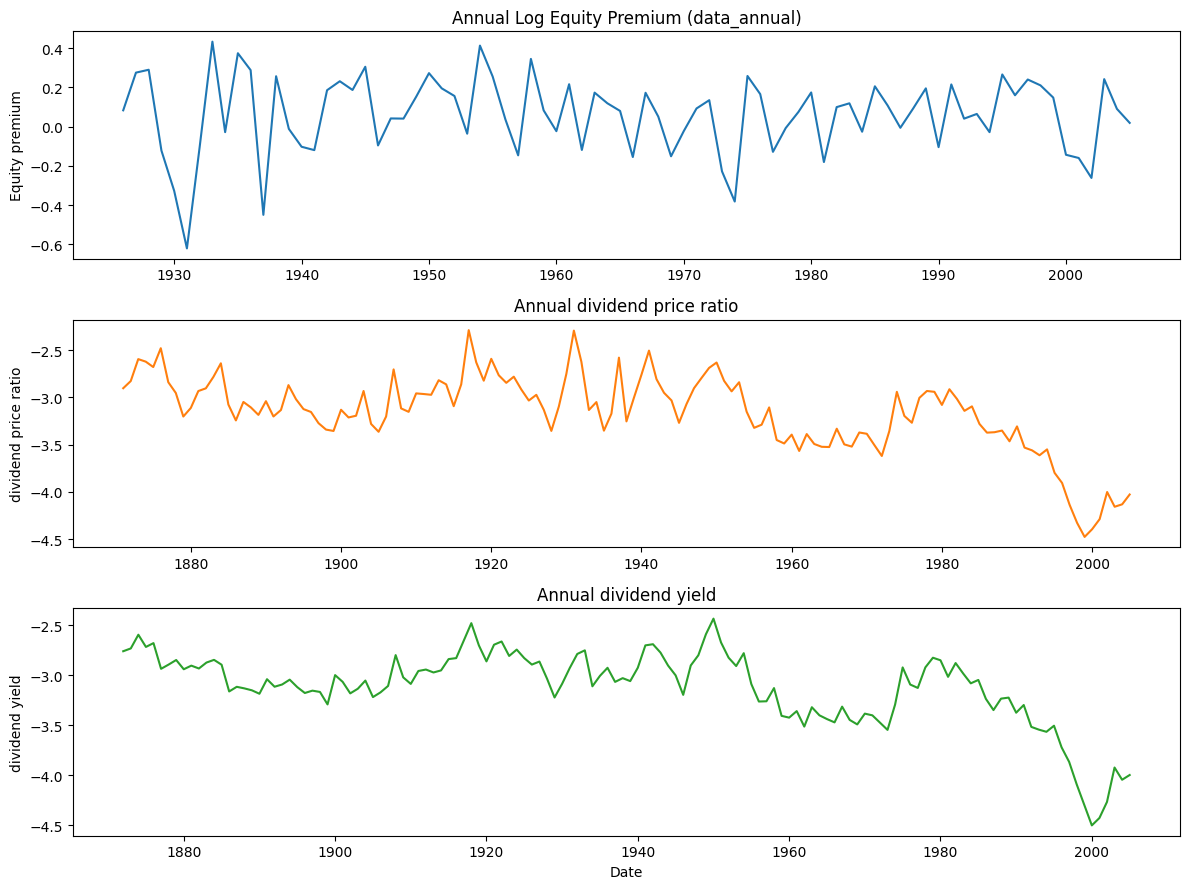

In [8]:
# plot premium over time
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=False)

# top: annual series from data_annual
axes[0].plot(data_annual.index, data_annual['equity_premium'], color='C0')
axes[0].set_title('Annual Log Equity Premium (data_annual)')
axes[0].set_ylabel('Equity premium')

# middle: annual series from computed annual dataframe
axes[1].plot(data_annual.index, data_annual['dp'], color='C1')
axes[1].set_title('Annual dividend price ratio')
axes[1].set_ylabel('dividend price ratio')

# bottom: monthly series (datetime index)
axes[2].plot(data_annual.index, data_annual['dy'], color='C2')
axes[2].set_title('Annual dividend yield')
axes[2].set_ylabel('dividend yield')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()


# Estadísticos

In [9]:
dep = 'equity_premium'
start = 1927; end = 2005
ts_in_sample = data_annual.loc[start:end] # Seleccionamos la muestra
# 1. Historical mean model
avg = ts_in_sample[dep].mean()
IS_error_mean = ts_in_sample[dep] - avg # Desviación de la media

In [14]:
# 2. Modelo OLS con una variable
# Creamos un variable independiente con un lag.
indep = 'ntis'# Emisiones de acciones
lagged_indep = ts_in_sample[indep].shift(1)
# Borramos NA por el lag
valid_idx = lagged_indep.dropna().index # Vector de años
y = ts_in_sample.loc[valid_idx, dep]
X = lagged_indep.loc[valid_idx]
X_const = add_constant(X)
reg = OLS(y, X_const).fit()
IS_error_cond = reg.resid

Vamos a estimar el varlor de $R^2$ y el ajustado por el tamaño:
$$
R^2=1-\frac{\sum_t(y_t-\hat{y_t})}{\sum_t(y_t-\bar{y}_t)}\\
\bar{R}^2=1-(1-R^2)\frac{n-1}{n-k-1}
$$
$n$: número de observaciones

$k$: número de predictores

In [28]:
IS_R2 = reg.rsquared
IS_R2_head = IS_R2 - (1 - IS_R2)*(len(IS_error_cond)-int(reg.df_resid))/(len(IS_error_cond)-1)
print(f"IS R^2: {IS_R2_head*100}")

IS R^2: 8.573863900971094


In [25]:
# OOS ANALISIS
est_periods_OOS = 20 # Número de años de entrenamiento inicial
OOS_error_M = []
OOS_error_C = []
for i in range(start + est_periods_OOS, end):
    # Actual Equity Risk Premium (ERP) en el año i+1
    actual_ERP = data_annual.loc[i+1, dep]
    # Error con la media histórica del periodo de entrenamiento
    avg_i = data_annual.loc[start:i, dep].mean()
    OOS_error_M.append(actual_ERP - avg_i)

    # Modelo OLS con una variable dependiente
    ts_train = data_annual.loc[start:i] # Seleccionamos la muestra de entrenamiento
    lagged_indep_train = ts_train[indep].shift(1) # Retardamos la variable explicativa
    valid_idx_train = lagged_indep_train.dropna().index # Seleccionamos los años
    y_train = ts_train.loc[valid_idx_train, dep]
    X_train = lagged_indep_train.loc[valid_idx_train]
    X_train_const = add_constant(X_train)
    reg_OOS = OLS(y_train, X_train_const).fit()

    # Prepramos los datos para la predicción
    x_new = data_annual.loc[i, indep] # es un valor
    x_new_df = pd.DataFrame({indep: [x_new]}) #Lo convertimos en un dataframe
    x_new_const = add_constant(x_new_df, has_constant='add')
    pred_ERP = reg_OOS.predict(x_new_const)[0] # Realizamos la predicción
    OOS_error_C.append(pred_ERP - actual_ERP)

In [26]:
MSE_M = np.mean(np.array(OOS_error_M)**2)
MSE_C = np.mean(np.array(OOS_error_C)**2)
OOS_R2 = 1 - (MSE_C / MSE_M)
T = len(valid_idx_train)
k = T - 1
OOS_R2_head = OOS_R2 - (1-OOS_R2)*(T-k)/(T-1)
print(f"OOS R^2: {OOS_R2_head*100}")
dRMSE = np.sqrt(MSE_M) - np.sqrt(MSE_C)
print(f"dRMSE: {dRMSE*100}")


OOS R^2: -5.594952810323077
dRMSE: -0.33855504273971604


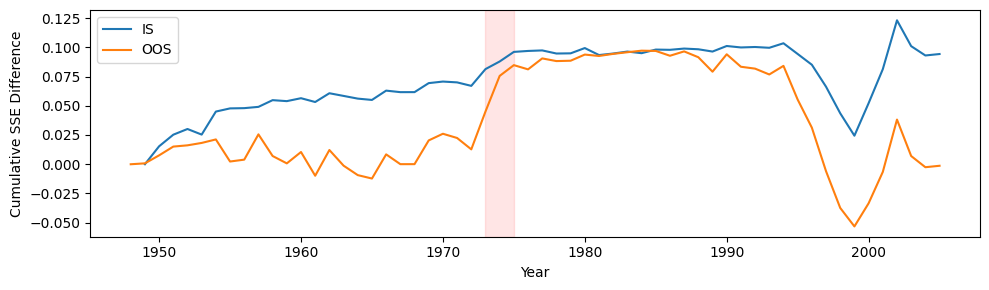

In [38]:
dp = help_get_stat(data_annual, indep='dp', dep='equity_premium', start=1927, end=2005, plot='yes')

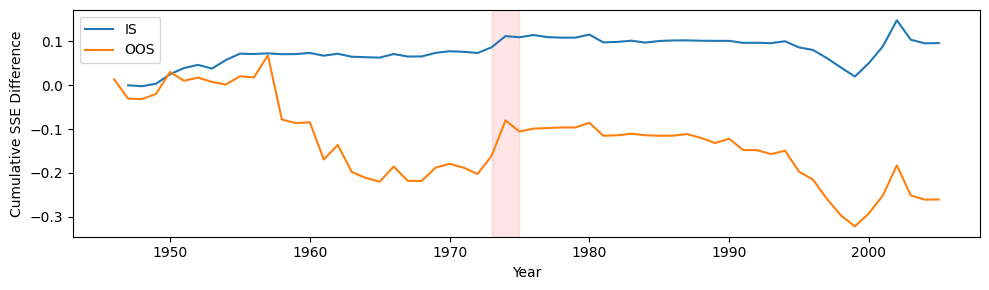

In [39]:
dy = help_get_stat(data_annual, indep='dy', dep='equity_premium', start=1925, end=2005, plot='yes')

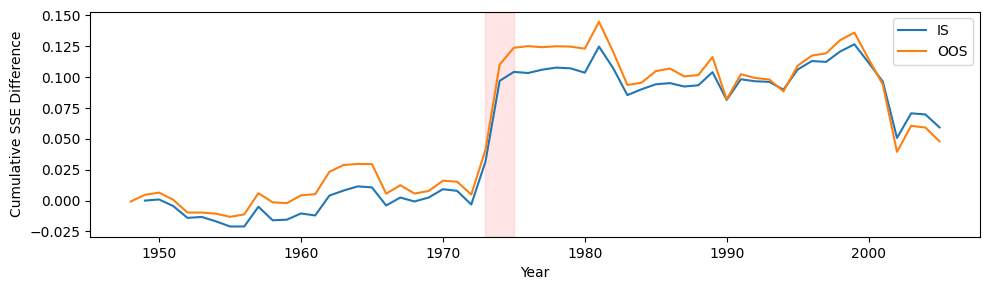

In [40]:
eqis = help_get_stat(data_annual, indep='eqis', dep='equity_premium', start=1927, end=2005, plot='yes')

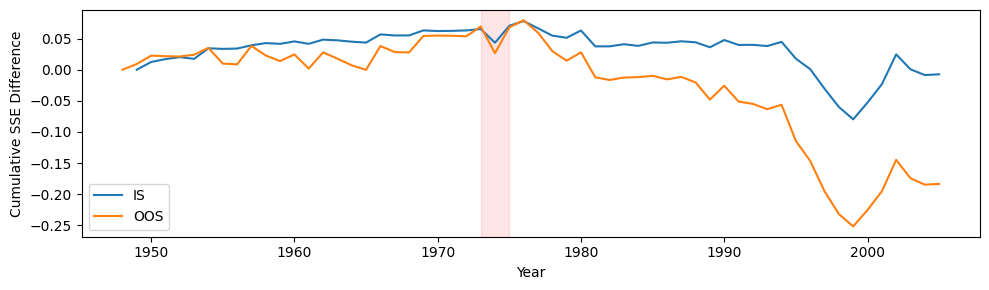

In [41]:
bm = help_get_stat(data_annual, indep='b/m', dep='equity_premium', start=1927, end=2005, plot='yes')


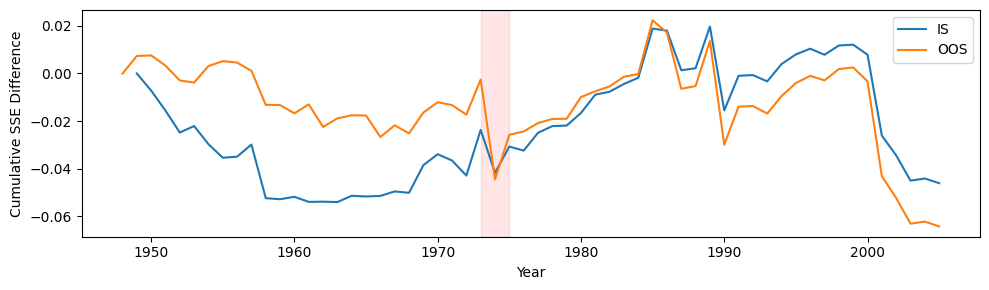

In [42]:
ntis = help_get_stat(data_annual, indep='ntis', dep='equity_premium', start=1927, end=2005, plot='yes')

# Bootstrap anual de Welch y Goyal (2008)

In [44]:
"""Bootstrap residual conjunto para regresiones anuales con un predictor.

Adaptación del procedimiento de Welch y Goyal (2008), horizonte de un año.
No reproduce automáticamente sus tablas: requiere misma muestra, datos,
convenciones y especificación. No cubre cay, selección de modelos ni restricciones.
Dependencias: numpy y pandas. No modifica los datos recibidos.
"""

def _estadisticos(y, x_lag, inicial):
    """Cada fila es una historia; las columnas son años consecutivos."""
    n = y.shape[1]
    sx = np.cumsum(x_lag, axis=1)
    sy = np.cumsum(y, axis=1)
    sxx = np.cumsum(x_lag**2, axis=1)
    sxy = np.cumsum(x_lag * y, axis=1)
    m = np.arange(1, n + 1, dtype=float)
    den = sxx - sx**2 / m
    tol = 1e-12 * np.maximum(1.0, sxx)
    if np.any(den[:, inicial - 1:] <= tol[:, inicial - 1:]):
        raise ValueError('Predictor constante o casi constante en una ventana.')
    # Índice inicial-1: estimación con exactamente inicial observaciones.
    sl = slice(inicial - 1, n - 1)
    beta = (sxy[:, sl] - sx[:, sl] * sy[:, sl] / m[sl]) / den[:, sl]
    media = sy[:, sl] / m[sl]
    alfa = media - beta * sx[:, sl] / m[sl]
    real = y[:, inicial:]
    e_n = real - media
    e_a = real - (alfa + beta * x_lag[:, inicial:])
    mse_n = np.mean(e_n**2, axis=1)
    mse_a = np.mean(e_a**2, axis=1)
    if np.any(mse_a <= 0):
        raise ValueError('Error cuadrático nulo: contraste degenerado.')
    t_oos = n - inicial
    # Horizonte anual de un año: h=1, por tanto factor T.
    mse_f = t_oos * (mse_n - mse_a) / mse_a
    b_full = (sxy[:, -1] - sx[:, -1] * sy[:, -1] / n) / den[:, -1]
    a_full = sy[:, -1] / n - b_full * sx[:, -1] / n
    resid = y - a_full[:, None] - b_full[:, None] * x_lag
    sse = np.sum(resid**2, axis=1)
    sst = np.sum((y - np.mean(y, axis=1, keepdims=True))**2, axis=1)
    if np.any(sse <= 0) or np.any(sst <= 0):
        raise ValueError('Regresión IS degenerada.')
    f_is = np.maximum(sst - sse, 0) / (sse / (n - 2))
    return dict(F_IS=f_is, MSE_F=mse_f, R2_IS=1 - sse / sst,
                R2_IS_ajustado=1 - (sse / sst) * (n - 1) / (n - 2),
                R2_OOS=1 - mse_a / mse_n,
                delta_RMSE=np.sqrt(mse_n) - np.sqrt(mse_a),
                MSE_N=mse_n, MSE_A=mse_a)


def bootstrap_anual(data_annual, indep='eqis', dep='equity_premium',
                    start=1927, end=2005, initial=20, B=10_000,
                    seed=2008, calcular_potencia=False):
    """Estima F IS, MSE-F OOS y su distribución bootstrap bajo H0: beta=0.

    Índice: años enteros, sin duplicados. Rentabilidades en tanto por uno.
    start/end delimitan AÑOS DE LA VARIABLE DEPENDIENTE.
    El retardo se construye antes de recortar: y_1927 usa x_1926 si existe.
    initial cuenta pares de regresión válidos, no años anteriores al retardo.
    Se admite recortar ausencias iniciales/finales; huecos internos se rechazan.
    Opcionalmente simula bajo la alternativa estimada para medir potencia.
    """
    if B < 100 or initial < 3:
        raise ValueError('Usa B>=100 e initial>=3.')
    if indep == dep:
        raise ValueError('Predictor y variable dependiente deben ser distintos.')
    d = data_annual[[dep, indep]].copy()
    d.index = pd.Index(pd.to_numeric(d.index, errors='raise').astype(int))
    d = d.sort_index()
    if d.index.has_duplicates:
        raise ValueError('Hay años duplicados.')
    # Reindexar evita que shift(1) confunda la fila previa con el año previo.
    d = d.reindex(range(int(d.index.min()), int(d.index.max()) + 1))
    d = d.apply(pd.to_numeric, errors='raise')
    z = pd.DataFrame({'y': d[dep], 'x': d[indep],
                      'x_lag': d[indep].shift(1)}).loc[start:end]
    z = z.replace([np.inf, -np.inf], np.nan).dropna()
    if len(z) <= initial + 1:
        raise ValueError('No hay suficientes años válidos para estimar y evaluar.')
    if not np.all(np.diff(z.index.to_numpy()) == 1):
        raise ValueError('Hay huecos internos: revisa la muestra antes de simular.')
    y, x, xl = (z[c].to_numpy(dtype=float) for c in ['y', 'x', 'x_lag'])
    n = len(z)
    obs_arrays = _estadisticos(y[None, :], xl[None, :], initial)
    observado = {k: float(v[0]) for k, v in obs_arrays.items()}
    X = np.column_stack([np.ones(n), xl])
    alpha_a, beta_a = np.linalg.lstsq(X, y, rcond=None)[0]
    mu, rho = np.linalg.lstsq(X, x, rcond=None)[0]
    alpha_n = y.mean()
    u2 = x - X @ np.array([mu, rho])
    rng = np.random.default_rng(seed)

    def simular(bajo_alternativa):
        if bajo_alternativa:
            alpha, beta = alpha_a, beta_a
            u1 = y - X @ np.array([alpha, beta])
        else:
            alpha, beta = alpha_n, 0.0
            u1 = y - alpha
        # Se sortean filas de la matriz (u1_t, u2_t), nunca columnas separadas.
        residuos = np.column_stack([u1, u2])
        residuos -= residuos.mean(axis=0)
        indices = rng.integers(0, n, size=(B, n))
        xp = rng.choice(xl, size=B, replace=True)
        ys = np.empty((B, n))
        xls = np.empty((B, n))
        for t in range(n):
            shocks = residuos[indices[:, t]]
            xls[:, t] = xp
            ys[:, t] = alpha + beta * xp + shocks[:, 0]
            xp = mu + rho * xp + shocks[:, 1]
        return pd.DataFrame(_estadisticos(ys, xls, initial))

    nulo = simular(False)
    # Corrección Monte Carlo: evita informar p=0 con B finito.
    pval = {k: (1 + np.sum(nulo[k] >= observado[k])) / (B + 1)
            for k in ['F_IS', 'MSE_F']}
    filas = []
    for k in ['F_IS', 'MSE_F']:
        filas.append({'contraste': k, 'estadistico': observado[k],
                      'p_bootstrap': pval[k],
                      'critico_90': nulo[k].quantile(.90),
                      'critico_95': nulo[k].quantile(.95),
                      'critico_99': nulo[k].quantile(.99)})
    resultado = dict(
        resumen=pd.DataFrame(filas).set_index('contraste'),
        observado=pd.Series(observado),
        muestra=pd.Series({'predictor': indep, 'primer_ano_estimacion': z.index[0],
                           'ultimo_ano': z.index[-1], 'n_regresion': n,
                           'entrenamiento_inicial': initial,
                           'primera_prediccion': z.index[initial],
                           'T_OOS': n - initial, 'B': B}),
        parametros=pd.Series({'alpha_H0': alpha_n, 'alpha_H1': alpha_a,
                              'beta_H1': beta_a, 'mu_AR1': mu, 'rho_AR1': rho}),
        simulaciones_H0=nulo,
    )
    if calcular_potencia:
        alternativa = simular(True)
        rechazo_is = alternativa.F_IS > nulo.F_IS.quantile(.95)
        rechazo_oos = alternativa.MSE_F > nulo.MSE_F.quantile(.95)
        resultado['potencia'] = pd.Series({
            'potencia_IS_5pct': rechazo_is.mean(),
            'potencia_OOS_5pct': rechazo_oos.mean(),
            'potencia_OOS_condicional_IS_5pct':
                rechazo_oos[rechazo_is].mean() if rechazo_is.any() else np.nan,
            'simulaciones_significativas_IS': int(rechazo_is.sum()),
        })
        resultado['simulaciones_H1'] = alternativa
    return resultado


In [45]:
resultado = bootstrap_anual(
    data_annual, indep="eqis", dep="equity_premium",
    start=1927, end=2005, initial=20, B=10_000, seed=2008,
    calcular_potencia=True,
)
display(resultado["muestra"])
display(resultado["resumen"].round(4))
display(resultado["observado"])
display(resultado["potencia"])

,0
predictor,eqis
primer_ano_estimacion,1928
ultimo_ano,2005
n_regresion,78
entrenamiento_inicial,20
primera_prediccion,1948
T_OOS,58
B,10000


,estadistico,p_bootstrap,critico_90,critico_95,critico_99
contraste,,,,,
F_IS,9.1785,0.0024,2.7761,3.9881,6.6617
MSE_F,2.3493,0.0267,0.3733,1.3450,3.7896


,0
F_IS,9.178481
MSE_F,2.349316
R2_IS,0.107756
R2_IS_ajustado,0.096016
R2_OOS,0.038929
delta_RMSE,0.003197
MSE_N,0.026444
MSE_A,0.025414


,0
potencia_IS_5pct,0.845800
potencia_OOS_5pct,0.751400
potencia_OOS_condicional_IS_5pct,0.860132
simulaciones_significativas_IS,8458.000000


In [46]:
# Tabla para varios predictores: 10.000 simulaciones por variable.
filas = []
for variable in ["dp", "dy", "eqis", "ntis", "b/m"]:
    r = bootstrap_anual(data_annual, indep=variable, start=1927, end=2005,
                        initial=20, B=10_000, seed=2008)
    filas.append({"variable": variable,
                  "T_OOS": r["muestra"]["T_OOS"],
                  "primer_ano_OOS": r["muestra"]["primera_prediccion"],
                  "R2_IS_ajustado_pct": 100*r["observado"]["R2_IS_ajustado"],
                  "p_IS": r["resumen"].loc["F_IS", "p_bootstrap"],
                  "R2_OOS_pct": 100*r["observado"]["R2_OOS"],
                  "MSE_F": r["observado"]["MSE_F"],
                  "p_OOS": r["resumen"].loc["MSE_F", "p_bootstrap"]})
display(pd.DataFrame(filas).set_index("variable"))

,T_OOS,primer_ano_OOS,R2_IS_ajustado_pct,p_IS,R2_OOS_pct,MSE_F,p_OOS
variable,,,,,,,
dp,59,1947,1.555271,0.183982,1.353945,0.809791,0.079992
dy,59,1947,2.676624,0.082192,-18.093071,-9.039406,0.993101
eqis,58,1948,9.601582,0.002400,3.892862,2.349316,0.026697
ntis,59,1947,7.166656,0.009799,-2.949565,-1.690384,0.530147
b/m,59,1947,3.695848,0.061294,-7.821519,-4.279940,0.853915
